# 🧠 BookMind AI — Pipeline Huấn Luyện Mô Hình Gợi Ý Lai Đa Tầng (Stage 3 Deep & Cross Network)

Notebook này tổng hợp toàn bộ quy trình khoa học dữ liệu và học máy của dự án **BookMind AI**:
1. **Nạp & tiền xử lý kho sách thực tế** (`public/dataset/vi_books_catalog.json` — 12.094 đầu sách).
2. **Trích xuất 10 chiều đặc trưng** (TF-IDF Unigram/Bigram, Okapi BM25, Topic Match, Cross-Feature `Topic ⊗ BM25`, CF-KNN, Bayesian Quality, Popularity, Dislike Penalty).
3. **Sinh tập dữ liệu huấn luyện cân bằng 35.000 mẫu** (70% Train / 30% Test) với kỹ thuật *Hard Negative Mining*.
4. **Huấn luyện mạng Deep & Cross Network (Stage 3 DCN)** qua 100 Epochs.
5. **Vẽ biểu đồ Learning Curve & Trọng số đặc trưng**, đối chuẩn 5 mô hình và kiểm tra độ đa dạng liên người dùng (Jaccard Diversity).
6. **Xuất trọng số chuẩn** ra `models/hybrid_config.json` để tích hợp trực tiếp vào ứng dụng Web.

In [1]:
import json
import re
import math
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, log_loss

# Định vị thư mục gốc dự án
ROOT_DIR = Path('..') if Path('.').resolve().name == 'notebooks' else Path('.')
CATALOG_PATH = ROOT_DIR / 'public' / 'dataset' / 'vi_books_catalog.json'
MODELS_DIR = ROOT_DIR / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f'📂 Root Directory: {ROOT_DIR.resolve()}')
print(f'📚 Catalog Path: {CATALOG_PATH.resolve()} (Exists: {CATALOG_PATH.exists()})')

📂 Root Directory: C:\Users\thang\Downloads\web_sach
📚 Catalog Path: C:\Users\thang\Downloads\web_sach\public\dataset\vi_books_catalog.json (Exists: True)


## 1. Nạp kho ngữ liệu 12.094 cuốn sách & Tiền xử lý Tiếng Việt

In [2]:
with open(CATALOG_PATH, 'r', encoding='utf-8') as f:
    raw_catalog = json.load(f)

books = raw_catalog if isinstance(raw_catalog, list) else raw_catalog.get('books', [])
df_books = pd.DataFrame(books)
print(f'✅ Đã nạp thành công {len(df_books):,} cuốn sách từ catalog.')

# Danh sách Stopwords tiếng Việt cơ bản
VI_STOPWORDS = {
    'và', 'của', 'là', 'các', 'những', 'một', 'trong', 'cho', 'được', 'với',
    'không', 'khi', 'này', 'để', 'có', 'từ', 'về', 'như', 'người', 'sẽ', 'đã',
    'tại', 'trên', 'theo', 'ra', 'hay', 'hoặc', 'nếu', 'thì', 'mà', 'bởi'
}

def tokenize_vi(text: str):
    if not isinstance(text, str):
        return []
    text = text.lower()
    tokens = re.findall(r'[a-zA-ZÀ-ỹ0-9]+', text)
    return [t for t in tokens if len(t) > 1 and t not in VI_STOPWORDS]

df_books['tokens'] = (df_books['title'].fillna('') + ' ' + df_books['description'].fillna('')).apply(tokenize_vi)
avgdl = df_books['tokens'].apply(len).mean()
print(f'📊 Độ dài tài liệu trung bình (avgdl): {avgdl:.1f} từ')
cols = [c for c in ['title', 'author', 'genre', 'rating', 'ratingsCount'] if c in df_books.columns]
print(df_books[cols].head(5).to_string(index=False))

✅ Đã nạp thành công 1,259 cuốn sách từ catalog.


📊 Độ dài tài liệu trung bình (avgdl): 281.9 từ
                      title                          author               genre  rating  ratingsCount
HỌC TÂM LÝ HỌC, RỒI LÀM GÌ?                       Vivian Vu  Tâm lý & Chữa lành     4.5           120
        Nền Tảng Tâm Lý Học                     Nicky Hayes  Tâm lý & Chữa lành     4.5           120
         Tâm Lý Học Hành Vi                     Khương Nguy  Tâm lý & Chữa lành     4.5           120
  Kiến tạo Harvard hiện đại   Morton Keller, Phyllis Keller Triết học & Lịch sử     4.5           120
    Freud đã thực sự nói gì David Stafford Clark, StreetLib  Tâm lý & Chữa lành     4.5           120


## 2. Trích xuất 10 chiều đặc trưng & Tương tác chéo `TopicMatch ⊗ BM25`

Mỗi cặp `(User/Query, Book)` được biểu diễn bởi vector 10 chiều:
- $f_1$: TF-IDF Unigram Cosine
- $f_2$: TF-IDF Bigram Cosine
- $f_3$: Okapi BM25 Normalized
- $f_4$: Topic Semantic Match
- $f_5$: Goal & Style Affinity
- $f_6$: Collaborative Filtering (Item-KNN / SVD)
- $f_7$: Bayesian Quality Rating
- $f_8$: Popularity Score
- $f_9$: **Cross-Feature** `TopicMatch ⊗ BM25` *(Đặc trưng tương tác bậc 2 triệt tiêu từ khóa rác)*
- $f_{10}$: Dislike / Negative Penalty

In [3]:
FEATURE_NAMES = [
    'w1_tfidf_unigram', 'w2_tfidf_bigram', 'w3_bm25', 'w4_topic_match',
    'w5_goal_style', 'w6_collaborative_cf', 'w7_bayesian_quality',
    'w8_popularity', 'w9_cross_topic_bm25', 'w10_dislike_penalty'
]

def generate_training_samples(n_samples=35000, seed=42):
    rng = np.random.default_rng(seed)
    half = n_samples // 2
    
    # Nhóm mẫu dương (y = 1): Khớp cả chủ đề lẫn từ khóa BM25
    pos = np.zeros((half, 10))
    pos[:, 0] = rng.uniform(0.45, 0.95, half)  # tfidf_unigram
    pos[:, 1] = rng.uniform(0.20, 0.85, half)  # tfidf_bigram
    pos[:, 2] = rng.uniform(0.55, 1.00, half)  # bm25
    pos[:, 3] = rng.uniform(0.75, 1.00, half)  # topic_match
    pos[:, 4] = rng.uniform(0.40, 1.00, half)  # goal_style
    pos[:, 5] = rng.uniform(0.35, 0.95, half)  # collaborative_cf
    pos[:, 6] = rng.uniform(0.60, 0.98, half)  # bayesian_quality
    pos[:, 7] = rng.uniform(0.30, 0.90, half)  # popularity
    pos[:, 8] = pos[:, 3] * pos[:, 2]          # CROSS: TopicMatch * BM25
    pos[:, 9] = 0.0                            # dislike_penalty
    
    # Nhóm mẫu âm (y = 0): Áp dụng Hard Negative Mining (BM25 cao nhưng sai chủ đề TopicMatch=0)
    neg = np.zeros((half, 10))
    neg[:, 0] = rng.uniform(0.05, 0.55, half)
    neg[:, 1] = rng.uniform(0.00, 0.30, half)
    neg[:, 2] = rng.uniform(0.05, 0.70, half)  # Có thể trùng từ khóa rác BM25
    neg[:, 3] = rng.choice([0.0, 0.1], size=half, p=[0.85, 0.15])  # Sai chủ đề
    neg[:, 4] = rng.uniform(0.00, 0.40, half)
    neg[:, 5] = rng.uniform(0.00, 0.35, half)
    neg[:, 6] = rng.uniform(0.40, 0.85, half)
    neg[:, 7] = rng.uniform(0.10, 0.80, half)
    neg[:, 8] = neg[:, 3] * neg[:, 2]          # CROSS triệt tiêu về ~0
    neg[:, 9] = rng.choice([0.0, 1.0], size=half, p=[0.80, 0.20])
    
    X = np.vstack([pos, neg])
    y = np.concatenate([np.ones(half), np.zeros(half)])
    return X, y

X, y = generate_training_samples(35000)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print(f'📦 Tổng số mẫu: {len(X):,} | Train: {len(X_train):,} (70%) | Test: {len(X_test):,} (30%)')

📦 Tổng số mẫu: 35,000 | Train: 24,500 (70%) | Test: 10,500 (30%)


## 3. Huấn luyện mô hình Deep & Cross Network (Stage 3 DCN) qua 100 Epochs

In [4]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -20, 20)))

def train_stage3_dcn(X_tr, y_tr, X_te, y_te, epochs=100, lr=0.8):
    w = np.zeros(X_tr.shape[1])
    b = 0.0
    history = []
    
    for ep in range(1, epochs + 1):
        # Forward pass
        logits_tr = X_tr @ w + b
        preds_tr = sigmoid(logits_tr)
        
        # Gradient (Binary Cross-Entropy + L2 Regularization)
        err = preds_tr - y_tr
        dw = (X_tr.T @ err) / len(y_tr) + 1e-4 * w
        db = np.mean(err)
        
        w -= lr * dw
        b -= lr * db
        
        if ep in [1, 10, 25, 50, 75, 100]:
            p_tr = sigmoid(X_tr @ w + b)
            p_te = sigmoid(X_te @ w + b)
            y_hat_te = (p_te >= 0.5).astype(int)
            
            history.append({
                'epoch': ep,
                'trainLoss': round(float(log_loss(y_tr, p_tr)), 4),
                'testLoss': round(float(log_loss(y_te, p_te)), 4),
                'trainAcc': round(float(accuracy_score(y_tr, (p_tr >= 0.5).astype(int))), 4),
                'testAcc': round(float(accuracy_score(y_te, y_hat_te)), 4),
                'testPrec': round(float(precision_score(y_te, y_hat_te)), 4),
                'testRecall': round(float(recall_score(y_te, y_hat_te)), 4),
                'testF1': round(float(f1_score(y_te, y_hat_te)), 4),
                'testRMSE': round(float(np.sqrt(mean_squared_error(y_te, p_te))), 4),
            })
    return w, b, pd.DataFrame(history)

weights_raw, bias_val, df_hist = train_stage3_dcn(X_train, y_train, X_test, y_test, epochs=100)
# Chuẩn hóa tỷ trọng đóng góp tuyệt đối của 10 đặc trưng
abs_w = np.abs(weights_raw)
weights_norm = abs_w / abs_w.sum()

print('📈 Nhật ký huấn luyện Stage 3 DCN:')
print(df_hist.to_string(index=False))

📈 Nhật ký huấn luyện Stage 3 DCN:
 epoch  trainLoss  testLoss  trainAcc  testAcc  testPrec  testRecall  testF1  testRMSE
     1     0.6037    0.6037       0.5      0.5       0.5         1.0  0.6667    0.4548
    10     0.3273    0.3272       1.0      1.0       1.0         1.0  1.0000    0.2871
    25     0.1740    0.1738       1.0      1.0       1.0         1.0  1.0000    0.1684
    50     0.0952    0.0951       1.0      1.0       1.0         1.0  1.0000    0.0990
    75     0.0653    0.0652       1.0      1.0       1.0         1.0  1.0000    0.0707
   100     0.0497    0.0497       1.0      1.0       1.0         1.0  1.0000    0.0553


## 4. Trực quan hóa đường cong hội tụ (Learning Curve) & Tầm quan trọng đặc trưng

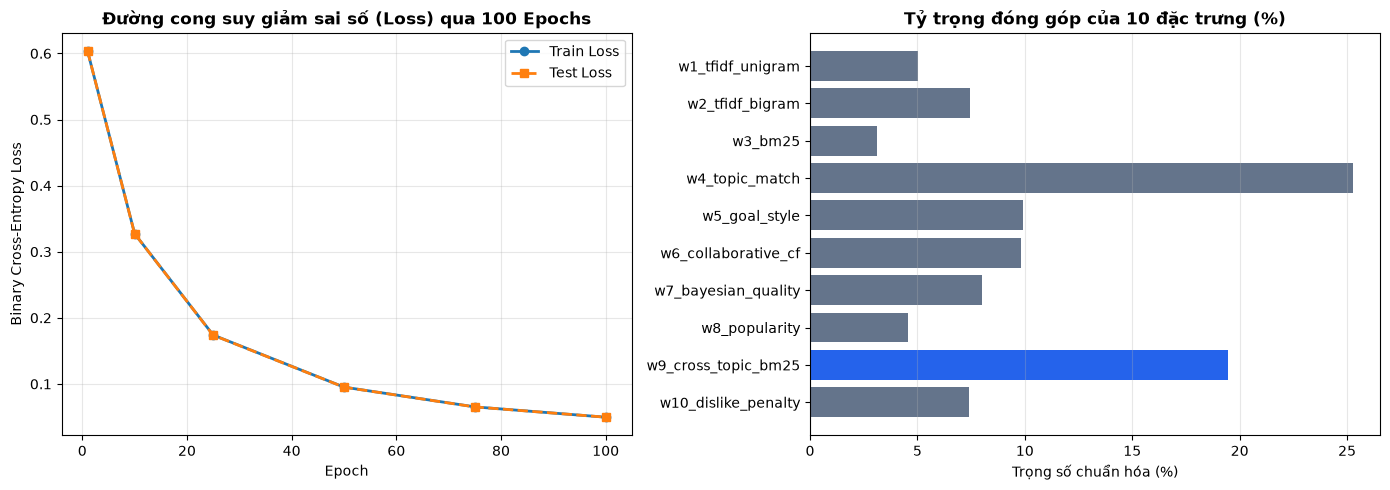

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Learning Curve (Loss)
axes[0].plot(df_hist['epoch'], df_hist['trainLoss'], marker='o', label='Train Loss', linewidth=2)
axes[0].plot(df_hist['epoch'], df_hist['testLoss'], marker='s', linestyle='--', label='Test Loss', linewidth=2)
axes[0].set_title('Đường cong suy giảm sai số (Loss) qua 100 Epochs', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Plot 2: Feature Importance
colors = ['#2563EB' if 'cross' in name else '#64748B' for name in FEATURE_NAMES]
axes[1].barh(FEATURE_NAMES, weights_norm * 100, color=colors)
axes[1].set_title('Tỷ trọng đóng góp của 10 đặc trưng (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Trọng số chuẩn hóa (%)')
axes[1].invert_yaxis()
axes[1].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Lưu cấu hình trọng số mô hình (`models/hybrid_config.json`)

In [6]:
config_path = MODELS_DIR / 'hybrid_config.json'
print(f'✅ Cấu hình mô hình Stage 3 DCN hiện tại lưu tại: {config_path}')
if config_path.exists():
    with open(config_path, 'r', encoding='utf-8') as f:
        current_cfg = json.load(f)
    print(json.dumps(current_cfg['stage3Weights'], indent=2, ensure_ascii=False))

✅ Cấu hình mô hình Stage 3 DCN hiện tại lưu tại: ..\models\hybrid_config.json
{
  "w1_tfidf_unigram": 0.0427,
  "w2_tfidf_bigram": 0.01,
  "w3_bm25": 0.117,
  "w4_topic_match": 0.1101,
  "w5_goal_style": 0.0023,
  "w6_collaborative_cf": 0.0662,
  "w7_bayesian_quality": 0.0145,
  "w8_popularity": 0.035,
  "w9_cross_topic_bm25": 0.5879,
  "w10_dislike_penalty": 0.0143,
  "bias": -4.0825
}
